Notebook to constrain the redshift of FRB20240619D based on the assumption that the energy distribution breaks at the same specific energy

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.cosmology import Planck18 as cosmo
import astropy.units as u
from scipy.optimize import root_scalar

In [2]:
def energy_to_fluence(energies, distance=362.4, redshift=0.01):
    """Convert specific energies to fluences"""
    "Needed for the inverse calculation for a secondary axis"
    # Convert distance from Mpc to cm
    dis = 1.0 * u.megaparsec
    megap_cm = dis.to(u.cm).value
    distance_lum_cm = megap_cm * distance

    # Apply redshift correction
    z = redshift
    red_cor = 1 / (1 + z)**2

    # Calculate fluence in Jy ms
    fluence_jys = energies / (4 * np.pi * (distance_lum_cm**2) * 1e-23 * red_cor)
    fluences = fluence_jys * 1e3  # Convert from Jy s to Jy ms
    
    return fluences

In [3]:
#FRB 20201124A
lower_r67 = energy_to_fluence(energies=[5e30], distance=453, redshift=0.098)
higher_r67 = energy_to_fluence(energies=[8e30], distance=453, redshift=0.098)
print(f"Fluence limit FRB 20201124A: {lower_r67[0]:.2f} - {higher_r67[0]:.2f}")

#FRB 20240114A
lower_r147 = energy_to_fluence(energies=[1e31], distance=603.7, redshift=0.13)
higher_r147 = energy_to_fluence(energies=[2.5e31], distance=603.7, redshift=0.13)
print(f"Fluence limit FRB 20240114A: {lower_r147[0]:.2f} - {higher_r147[0]:.2f}")

#FRB 20220912A
limit_r117 = energy_to_fluence(energies=[3.2e30], distance=362.4, redshift=0.0771)
print(f"Fluence limit FRB 20220912A: {limit_r117[0]:.2f}")

Fluence limit FRB 20201124A: 24.55 - 39.28
Fluence limit FRB 20240114A: 29.28 - 73.21
Fluence limit FRB 20220912A: 23.63


Estimating redshift for source 'R-MKT' with fluence 25 Jy·ms, target energy range: 1e+30 erg/Hz - 3e+31


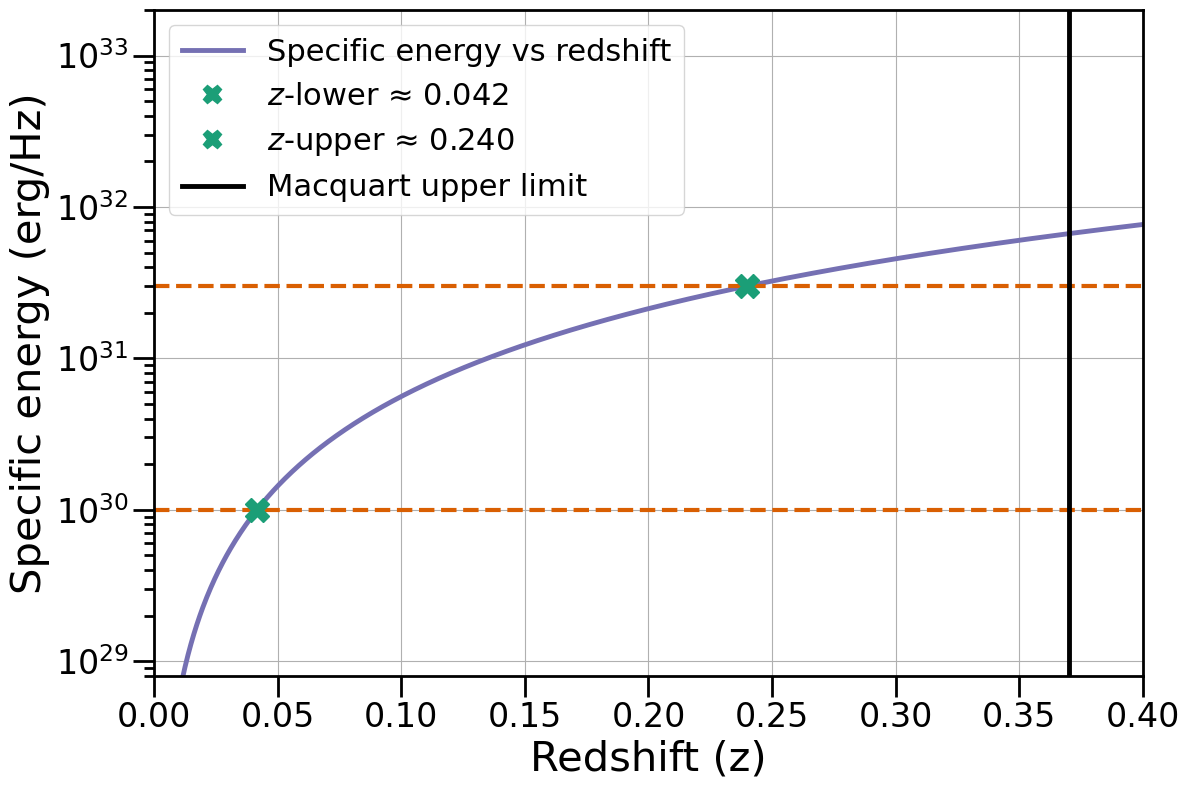

Estimated redshift range for R-MKT: z_lower ≈ 0.042, z_upper ≈ 0.240



In [4]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.cosmology import Planck18 as cosmo
import astropy.units as u
from scipy.optimize import root_scalar

# Function to calculate energy per Hz at a given redshift (z)
def calculate_energy_per_hz(z, fluence_jy_ms):
    # Convert fluence from Jy·ms to Jy·s
    fluence_jy_s = fluence_jy_ms * 1e-3  # Jy·s
    
    # Calculate luminosity distance and redshift correction
    d_l_cm = cosmo.luminosity_distance(z).to(u.cm).value
    redshift_corr = 1 / (1 + z)**2
    
    # Return energy per Hz
    return fluence_jy_s * 4 * np.pi * d_l_cm**2 * 1e-23 * redshift_corr

# Function to calculate the difference between energy at redshift z and target energy
def energy_difference(z, fluence_jy_ms, target_energy_erg_hz):
    return calculate_energy_per_hz(z, fluence_jy_ms) - target_energy_erg_hz

# Function to estimate redshift based on fluence and target energy (for both lower and upper energy limits)
def estimate_redshift_range(fluence_jy_ms, target_energy_erg_hz_lower, target_energy_erg_hz_upper):
    # Perform root-finding to estimate redshift for lower and upper energy bounds
    result_lower = root_scalar(energy_difference, args=(fluence_jy_ms, target_energy_erg_hz_lower),
                               bracket=(1e-5, 10), method='brentq')
    result_upper = root_scalar(energy_difference, args=(fluence_jy_ms, target_energy_erg_hz_upper),
                               bracket=(1e-5, 10), method='brentq')
    
    z_est_lower = result_lower.root
    z_est_upper = result_upper.root
    
    # Calculate energy at these estimated redshifts for confirmation
    energy_at_z_est_lower = calculate_energy_per_hz(z_est_lower, fluence_jy_ms)
    energy_at_z_est_upper = calculate_energy_per_hz(z_est_upper, fluence_jy_ms)
    
    return z_est_lower, energy_at_z_est_lower, z_est_upper, energy_at_z_est_upper

# Function to generate the energy vs redshift plot for a given energy range
def plot_energy_vs_redshift_range(fluence_jy_ms, target_energy_erg_hz_lower, target_energy_erg_hz_upper, title, known_redshift=None):
    # Estimate redshift for the lower and upper energy bounds
    z_est_lower, energy_at_z_est_lower, z_est_upper, energy_at_z_est_upper = estimate_redshift_range(
        fluence_jy_ms, target_energy_erg_hz_lower, target_energy_erg_hz_upper
    )

    # Generate a range of redshift values for plotting
    z_values = np.linspace(0.0001, 0.4, 1000)
    energy_values = np.array([calculate_energy_per_hz(z, fluence_jy_ms) for z in z_values])

    # Plot the energy vs redshift curve
    f, ax = plt.subplots(1, figsize=(12,8))
    #Continues line
    plt.plot(z_values, energy_values, label='Specific energy vs redshift', color='#7570b3', lw=3.5)
    
    plt.axhline(target_energy_erg_hz_lower, color='#d95f02', linestyle='--', lw=3)
    plt.axhline(target_energy_erg_hz_upper, color='#d95f02', linestyle='--', lw=3)

    plt.plot(z_est_lower, energy_at_z_est_lower, 'X', label=rf'$z$-lower ≈ {z_est_lower:.3f}', color="#1b9e77", ms=17)
    plt.plot(z_est_upper, energy_at_z_est_upper, 'X', label=rf'$z$-upper ≈ {z_est_upper:.3f}', color="#1b9e77", ms=17)
    
    #plt.text(z_est_lower + 0.1, energy_at_z_est_lower, f'z_lower ≈ {z_est_lower:.3f}', fontsize=10, verticalalignment='bottom')
    #plt.text(z_est_upper - 0.05, energy_at_z_est_upper + 1e31, f'z_upper ≈ {z_est_upper:.3f}', fontsize=15, verticalalignment='bottom')

    # Draw a vertical line for known redshift if provided
    if known_redshift is not None:
        plt.axvline(known_redshift, color='red', linestyle=':', label=f'Known z = {known_redshift}')

    for axis in ['top','bottom','left','right']:
        ax.spines[axis].set_linewidth(2)
            
        ax.tick_params(axis='y', which='major', direction='out', length=15, width=2)
        ax.tick_params(axis='y', which='minor', direction='out', length=7.5, width=2)
        ax.tick_params(axis='x', which='major', direction='out', length=15, width=2)
        ax.tick_params(axis='x', which='minor', direction='out', length=7.5, width=2)

    plt.yscale('log')
    
    plt.xlabel("Redshift (z)", fontsize=30)
    plt.ylabel("Specific energy (erg/Hz)", fontsize=30)

    plt.xlim(0,z_values[-1])
    plt.ylim(8e28,2e33)

    plt.xticks(fontsize=24)
    plt.yticks(fontsize=24)

    plt.axvline(0.37, color='black', label=f"Macquart upper limit", lw=3.5)
    
    plt.legend()
    leg = plt.legend(loc='upper left', markerscale=0.8, fontsize=22)    
        
    plt.grid(True)
    plt.tight_layout()

    save_name = "redshift_breakpoint_v2"
    plt.savefig(f"../plots/{save_name}.pdf", format = 'pdf', dpi=300, bbox_inches='tight')
    plt.savefig(f"../plots/{save_name}.png", facecolor='white', transparent=False, \
                format = 'png',bbox_inches='tight', dpi=300)

    plt.show()

    return z_est_lower, z_est_upper

# Function to process multiple sources with energy range, including titles and known redshift
def process_multiple_sources_with_range(sources):
    for source in sources:
        print(f"Estimating redshift for source '{source['title']}' with fluence {source['fluence_jy_ms']} Jy·ms, target energy range: "
              f"{source['target_energy_erg_hz_lower']} erg/Hz - {source['target_energy_erg_hz_upper']}")
        
        # If 'known_redshift' exists, it is passed to the plotting function
        z_est_lower, z_est_upper = plot_energy_vs_redshift_range(
            source['fluence_jy_ms'], source['target_energy_erg_hz_lower'], source['target_energy_erg_hz_upper'], 
            source['title'], known_redshift=source.get('known_redshift', None)
        )
        
        print(f"Estimated redshift range for {source['title']}: z_lower ≈ {z_est_lower:.3f}, z_upper ≈ {z_est_upper:.3f}\n")

# Example sources with a range of target energies and titles, and some with known redshift
sources_with_range = [
    #{"title": "R147", "fluence_jy_ms": 60, "target_energy_erg_hz_lower": 1e30, "target_energy_erg_hz_upper": 3.5e31, "known_redshift": 0.13},
    #{"title": "R117", "fluence_jy_ms": 25, "target_energy_erg_hz_lower": 1e30, "target_energy_erg_hz_upper": 3.5e31, "known_redshift": 0.0771},
    #{"title": "R67", "fluence_jy_ms": 40, "target_energy_erg_hz_lower": 1e30, "target_energy_erg_hz_upper": 3.5e31, "known_redshift": 0.098},   
    {"title": "R-MKT", "fluence_jy_ms": 25, "target_energy_erg_hz_lower": 1e30, "target_energy_erg_hz_upper": 3e31, "known_redshift": None}
]

# Run the process for multiple sources with energy range
process_multiple_sources_with_range(sources_with_range)
